In [1]:
# Kaggle setup: clone the repo (src/ code), install libraries, find the competition data.
# Needs: Internet ON, competition data added as input.
import os, glob, subprocess

REPO = "polluvl/hw2-video-detection"

if os.path.isdir("/kaggle/working"):
    # 1. clone the repo once per session
    if not os.path.isdir("/kaggle/working/repo"):
        r = subprocess.run(["git", "clone", "-q", f"https://github.com/{REPO}.git", "/kaggle/working/repo"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("git clone failed (is Internet on?):\n" + r.stderr)
    # 2. install the pinned libraries
    subprocess.run(["pip", "install", "-q", "-r", "/kaggle/working/repo/requirements.txt"], check=True)
    os.chdir("/kaggle/working/repo/notebooks")

    # 3. find where Kaggle mounted the competition data
    hits = glob.glob("/kaggle/input/**/test_images.csv", recursive=True)
    if not hits:
        raise RuntimeError("Competition data not found: add it in the right panel under Input")
    os.environ["DATA_ROOT"] = os.path.dirname(hits[0])
    print("data root:", os.environ["DATA_ROOT"])

data root: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


# 02 · Two-stage anchor-based: Faster R-CNN (torchvision, ResNet-50-FPN v2, COCO-pretrained)

**Fixed protocol (same for 03 RetinaNet):**
train = every `TRAIN_STEP`-th frame of the 56 train clips, val = every `VAL_STEP`-th frame of
the 7 val clips (split by sequence, given by the organisers). Images resized to short side 800 /
long side ≤ 1333 inside the model, horizontal flip + brightness/contrast jitter, ignored regions
painted with the mean colour during training. SGD (momentum 0.9, wd 1e-4), lr 0.01, batch 4,
300-iteration warmup + cosine, AMP, `EPOCHS` epochs, best epoch by val mAP.
Evaluation: COCO mAP@[.5:.95], AP50, AP_small with maxDets=500 and ignored regions as iscrowd.

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, str(Path("../src").resolve()))
sys.path.insert(0, str(Path("src").resolve()))
from analysis import (draw_errors, error_breakdown, recall_by_size,
                      summarise_errors, worst_frames)
from common import (SMOKE, evaluate, evaluate_per_clip, find_data_root,
                    list_frames, log_result, save_preds, seed_everything, work_dir)
from tv_detection import build_faster_rcnn, predict, train_detector

# stop right away if there is no GPU (a CPU run would time out after 12 h)
assert torch.cuda.is_available(), "No GPU! Session options -> Accelerator -> GPU"
print("GPU:", torch.cuda.get_device_name(0))

DATA = find_data_root()
OUT = work_dir()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAIN_STEP, VAL_STEP, EPOCHS = (1, 1, 1) if SMOKE else (10, 5, 5)
train_frames = list_frames(DATA / "train", step=TRAIN_STEP)
val_frames = list_frames(DATA / "val", step=VAL_STEP)
print(f"device {DEVICE} | train {len(train_frames)} frames | val {len(val_frames)} frames")

BASE = dict(epochs=EPOCHS, batch_size=2 if SMOKE else 4, lr=0.01, num_workers=2,
            min_size=800, max_size=1333)
if SMOKE:
    BASE.update(min_size=192, max_size=320, print_every=5)

GPU: Tesla T4
device cuda | train 2446 frames | val 571 frames


## Experiments
Each run changes ONE thing relative to the baseline:
- `frcnn_base` – torchvision defaults (Smooth-L1 box loss, 512 RoIs/image, 25 % positives)
- `frcnn_giou` – loss modification: GIoU loss for the second-stage box regression
- `frcnn_roi`  – RoI sampling: 256 RoIs with 50 % positives (many small objects per image →
  more positive RoIs per GT)

The number of RPN proposals at test time is checked afterwards **without retraining** (cheap).

In [3]:
RUNS = {
    "frcnn_base": {},
    "frcnn_giou": {"box_loss": "giou"},
    "frcnn_roi": {"roi_batch_size": 256, "roi_pos_fraction": 0.5},
}

histories = {}
for name, changes in RUNS.items():
    seed_everything(42)
    cfg = {**BASE, **changes}
    print(f"\n=== {name}: {changes}")
    model = build_faster_rcnn(cfg, pretrained=not SMOKE)
    histories[name] = train_detector(model, train_frames, val_frames, cfg, DEVICE, OUT / f"{name}.pt")

    preds, ms = predict(model, val_frames, DEVICE)
    save_preds(preds, OUT / f"preds_val_{name}.npz")
    metrics = evaluate(val_frames, preds)
    log_result(name, metrics, {"family": "two-stage", "ms_per_img": round(ms, 1),
                               "train_min": round(sum(h["train_min"] for h in histories[name]), 1),
                               "config": str(changes)})
    print(name, metrics, f"{ms:.1f} ms/img")
    del model
    torch.cuda.empty_cache()


=== frcnn_base: {}
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 233MB/s]
/kaggle/working/repo/src/tv_detection.py:282: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


  step 200/3055 loss 1.018 lr 0.00667
  step 400/3055 loss 0.792 lr 0.00997
  step 600/3055 loss 0.885 lr 0.00971
epoch 1: mAP 0.2024 AP50 0.4205 AP_s 0.0952 (7.5 min)
  step 800/3055 loss 0.736 lr 0.00922
  step 1000/3055 loss 0.896 lr 0.00850
  step 1200/3055 loss 0.790 lr 0.00761
epoch 2: mAP 0.2148 AP50 0.4497 AP_s 0.1037 (7.4 min)
  step 1400/3055 loss 0.748 lr 0.00659
  step 1600/3055 loss 0.548 lr 0.00549
  step 1800/3055 loss 0.634 lr 0.00436
epoch 3: mAP 0.2335 AP50 0.4701 AP_s 0.0995 (7.4 min)
  step 2000/3055 loss 0.600 lr 0.00327
  step 2200/3055 loss 0.582 lr 0.00227
  step 2400/3055 loss 0.685 lr 0.00142
epoch 4: mAP 0.2369 AP50 0.4803 AP_s 0.1038 (7.4 min)
  step 2600/3055 loss 0.561 lr 0.00075
  step 2800/3055 loss 0.617 lr 0.00031
  step 3000/3055 loss 0.458 lr 0.00011
epoch 5: mAP 0.2384 AP50 0.4763 AP_s 0.1033 (7.4 min)
frcnn_base {'mAP': 0.2384, 'AP50': 0.4763, 'AP75': 0.207, 'AP_small': 0.1033, 'AP_medium': 0.2209, 'AP_large': 0.4263, 'AR': 0.4521} 240.2 ms/img

==

/kaggle/working/repo/src/tv_detection.py:282: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


  step 200/3055 loss 1.595 lr 0.00667
  step 400/3055 loss 1.303 lr 0.00997
  step 600/3055 loss 1.408 lr 0.00971
epoch 1: mAP 0.1959 AP50 0.4164 AP_s 0.0916 (6.7 min)
  step 800/3055 loss 1.164 lr 0.00922
  step 1000/3055 loss 1.333 lr 0.00850
  step 1200/3055 loss 1.254 lr 0.00761
epoch 2: mAP 0.1934 AP50 0.4180 AP_s 0.0832 (6.7 min)
  step 1400/3055 loss 1.227 lr 0.00659
  step 1600/3055 loss 0.851 lr 0.00549
  step 1800/3055 loss 0.919 lr 0.00436
epoch 3: mAP 0.2197 AP50 0.4513 AP_s 0.0957 (6.7 min)
  step 2000/3055 loss 0.981 lr 0.00327
  step 2200/3055 loss 0.914 lr 0.00227
  step 2400/3055 loss 1.030 lr 0.00142
epoch 4: mAP 0.2186 AP50 0.4525 AP_s 0.1002 (6.7 min)
  step 2600/3055 loss 0.915 lr 0.00075
  step 2800/3055 loss 0.966 lr 0.00031
  step 3000/3055 loss 0.730 lr 0.00011
epoch 5: mAP 0.2203 AP50 0.4480 AP_s 0.1059 (6.7 min)
frcnn_roi {'mAP': 0.2203, 'AP50': 0.448, 'AP75': 0.1869, 'AP_small': 0.1059, 'AP_medium': 0.2097, 'AP_large': 0.404, 'AR': 0.4364} 240.2 ms/img


## Learning curves and results table

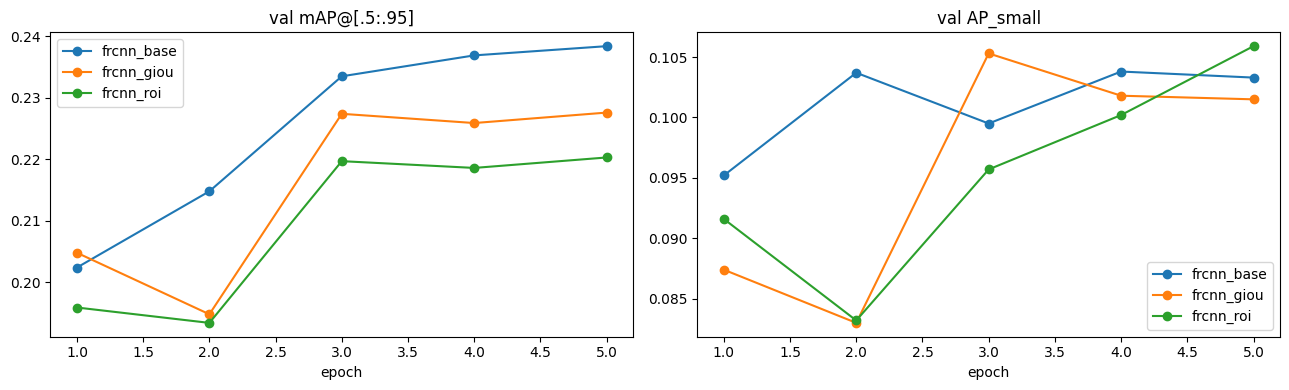

,experiment,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,family,ms_per_img,train_min,config
0,frcnn_base,0.2384,0.4763,0.2070,0.1033,0.2209,0.4263,0.4521,two-stage,240.2,37.0,{}
1,frcnn_giou,0.2276,0.4545,0.1977,0.1015,0.2131,0.4171,0.4503,two-stage,240.3,37.0,{'box_loss': 'giou'}
2,frcnn_roi,0.2203,0.4480,0.1869,0.1059,0.2097,0.4040,0.4364,two-stage,240.2,33.6,"{'roi_batch_size': 256, 'roi_pos_fraction': 0.5}"


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    h = pd.DataFrame(h)
    axes[0].plot(h.epoch, h.mAP, marker="o", label=name)
    axes[1].plot(h.epoch, h.AP_small, marker="o", label=name)
axes[0].set_title("val mAP@[.5:.95]")
axes[1].set_title("val AP_small")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT / "figures_frcnn_curves.png", dpi=120)
plt.show()

results = pd.read_csv(OUT / "results.csv")
results[results.experiment.str.startswith("frcnn")]

## Number of RPN proposals at test time (no retraining)
Dense frames can contain hundreds of objects; with too few proposals some objects never
reach the second stage.

In [5]:
best_name = results[results.experiment.isin(RUNS)].sort_values("mAP").experiment.iloc[-1]
print("best run:", best_name)
model = build_faster_rcnn({**BASE, **RUNS[best_name]}, pretrained=False)
model.load_state_dict(torch.load(OUT / f"{best_name}.pt", map_location=DEVICE))
model.to(DEVICE)

sweep = []
for n_prop in [300, 1000, 2000, 3000]:
    model.rpn._pre_nms_top_n["testing"] = max(n_prop, 1000)
    model.rpn._post_nms_top_n["testing"] = n_prop
    p, ms = predict(model, val_frames, DEVICE)
    sweep.append({"proposals": n_prop, **evaluate(val_frames, p), "ms_per_img": round(ms, 1)})
sweep = pd.DataFrame(sweep)
print(sweep[["proposals", "mAP", "AP50", "AP_small", "AR", "ms_per_img"]])
model.rpn._pre_nms_top_n["testing"] = 1000
model.rpn._post_nms_top_n["testing"] = 1000

best run: frcnn_base
   proposals     mAP    AP50  AP_small      AR  ms_per_img
0        300  0.2366  0.4732    0.1032  0.4410       205.0
1       1000  0.2384  0.4763    0.1033  0.4521       240.1
2       2000  0.2389  0.4827    0.1084  0.4650       290.7
3       3000  0.2363  0.4791    0.1082  0.4641       343.4


## What does each stage contribute?
Recall of the **RPN proposals** (class-agnostic, before the second stage) versus the **final
detections**, at IoU 0.5 and 0.7, by object size. The RPN decides which objects can be found at
all; the second stage classifies them and refines the box.

In [6]:
from analysis import SIZE_BINS, SIZE_LABELS, box_iou
from common import read_labels
from tv_detection import DroneDataset, collate
from torch.utils.data import DataLoader


@torch.no_grad()
def rpn_proposals(model, frames):
    model.eval()
    out = {}
    loader = DataLoader(DroneDataset(frames), batch_size=2, collate_fn=collate)
    for images, _, keys in loader:
        orig_sizes = [img.shape[-2:] for img in images]
        image_list, _ = model.transform([img.to(DEVICE) for img in images])
        features = model.backbone(image_list.tensors)
        proposals, _ = model.rpn(image_list, features)
        for key, props, (h0, w0), (h1, w1) in zip(keys, proposals, orig_sizes, image_list.image_sizes):
            scale = torch.tensor([w0 / w1, h0 / h1, w0 / w1, h0 / h1], device=props.device)
            out[key] = (props * scale).cpu().numpy()
    return out


def recall_table(frames, boxes_by_key, iou_thr, score_thr=None):
    hits, sizes = [], []
    for r in frames.itertuples():
        gt, _ = read_labels(r.label_path, r.width, r.height)
        b = boxes_by_key.get(r.image_key, np.zeros((0, 6)))
        if score_thr is not None and len(b):
            b = b[b[:, 4] >= score_thr]
        iou = box_iou(gt, b[:, :4]) if len(b) else np.zeros((len(gt), 0))
        hits += list(iou.max(axis=1) >= iou_thr) if iou.shape[1] else [False] * len(gt)
        sizes += list(np.sqrt((gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1])))
    df = pd.DataFrame({"hit": hits, "size_bin": pd.cut(sizes, SIZE_BINS, labels=SIZE_LABELS)})
    return df.groupby("size_bin", observed=False).hit.mean().round(3)


props = rpn_proposals(model, val_frames)
best_preds, _ = predict(model, val_frames, DEVICE)
stage_table = pd.DataFrame({
    "RPN proposals (1000) IoU≥0.5": recall_table(val_frames, props, 0.5),
    "RPN proposals IoU≥0.7": recall_table(val_frames, props, 0.7),
    "final dets (score≥0.05) IoU≥0.5": recall_table(val_frames, best_preds, 0.5, 0.05),
    "final dets IoU≥0.7": recall_table(val_frames, best_preds, 0.7, 0.05),
})
stage_table
# (final-detection recall here is class-agnostic too, so it is directly comparable to the RPN)

,RPN proposals (1000) IoU≥0.5,RPN proposals IoU≥0.7,final dets (score≥0.05) IoU≥0.5,final dets IoU≥0.7
size_bin,,,,
tiny <16,0.208,0.039,0.208,0.026
small 16-32,0.664,0.354,0.587,0.265
medium 32-96,0.815,0.608,0.757,0.500
large >96,0.990,0.951,0.973,0.868


## Failure cases (score threshold 0.3)

GT outcome by size:
 outcome          TP  missed  poor_loc  wrong_class   n_gt
size_bin                                                 
tiny <16      0.117   0.545     0.286        0.052     77
small 16-32   0.451   0.338     0.155        0.056   4318
medium 32-96  0.629   0.199     0.103        0.069  15916
large >96     0.825   0.061     0.007        0.107   2595 

GT outcome by class:
 outcome      TP  missed  poor_loc  wrong_class
class                                         
bicycle   0.467   0.149     0.054        0.329
bus       0.075   0.170     0.000        0.755
car       0.648   0.239     0.100        0.013
motor     0.512   0.321     0.055        0.113
person    0.692   0.155     0.142        0.012
tricycle  0.467   0.319     0.030        0.184
truck     0.587   0.347     0.022        0.044
van       0.366   0.243     0.034        0.357 

False positives:
 type
background     2995
poor_loc       2473
wrong_class    2464
duplicate       108
Name: count, dtype: int64

per-c

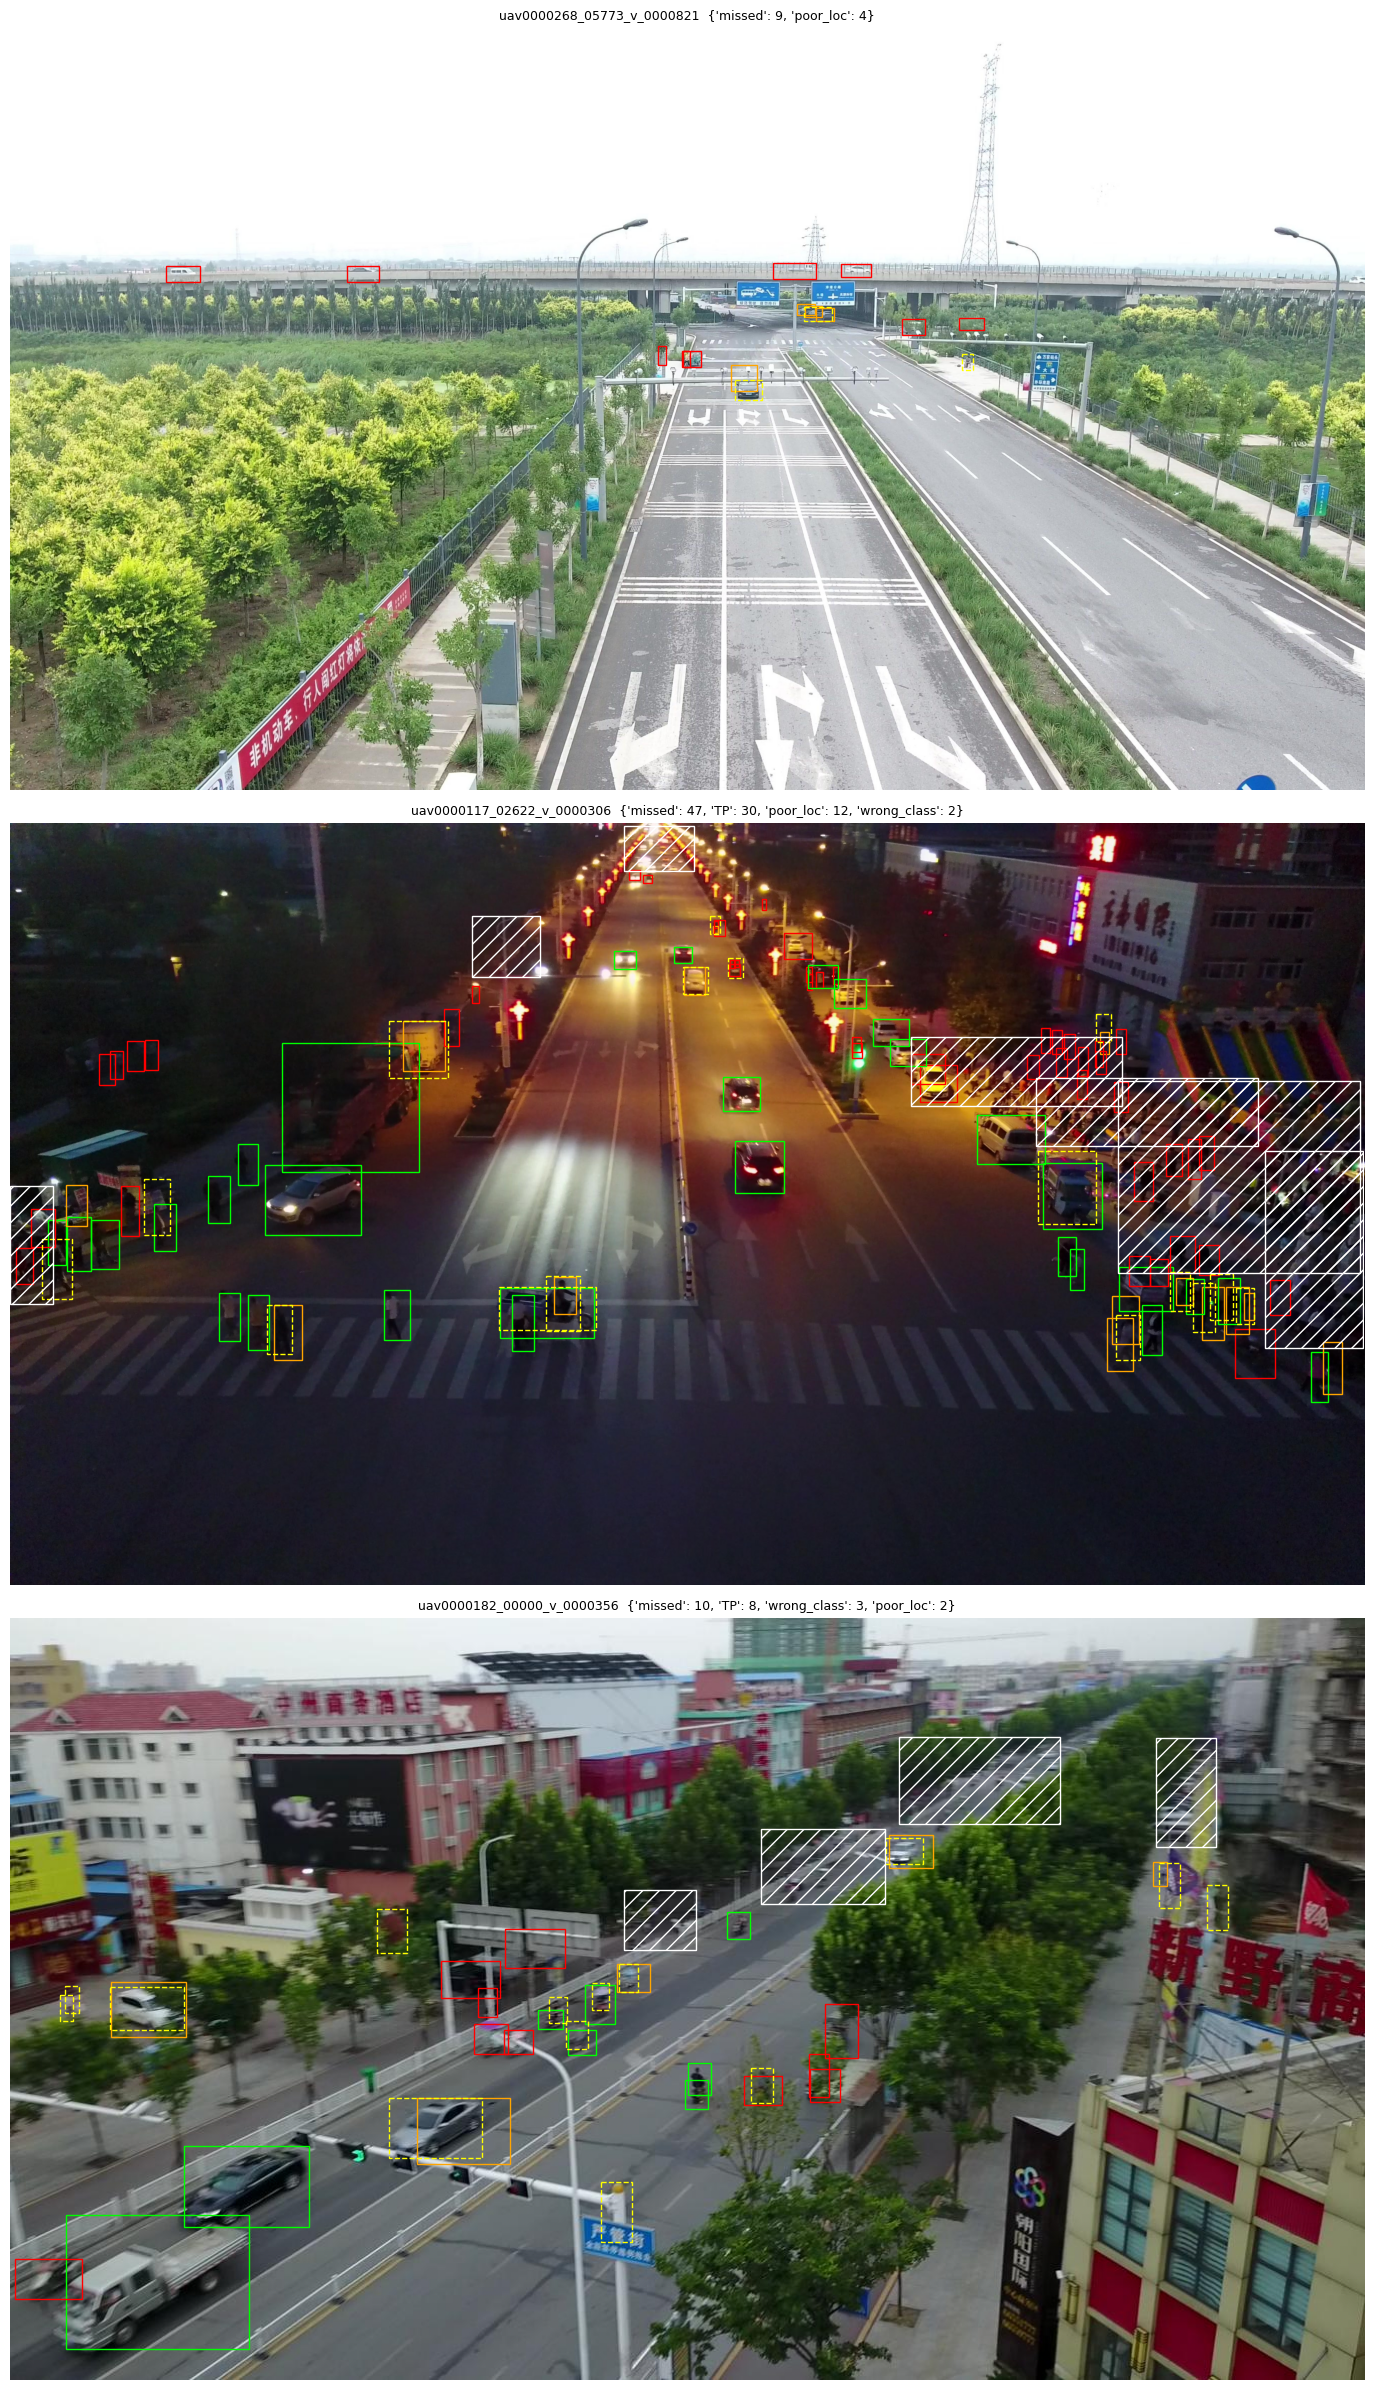

In [7]:
gts, fps = error_breakdown(val_frames, best_preds, score_thr=0.3)
by_size, by_class, fp_types = summarise_errors(gts, fps)
print("GT outcome by size:\n", by_size, "\n\nGT outcome by class:\n", by_class, "\n\nFalse positives:\n", fp_types)
print("\nper-clip mAP:\n", evaluate_per_clip(val_frames, best_preds))

worst = worst_frames(gts, val_frames, k=3)
fig, axes = plt.subplots(len(worst), 1, figsize=(14, 8 * len(worst)))
for ax, row in zip(np.atleast_1d(axes), worst.itertuples()):
    draw_errors(ax, row, best_preds[row.image_key], score_thr=0.3)
plt.tight_layout()
plt.savefig(OUT / "figures_frcnn_failures.png", dpi=100)
plt.show()

TODO (your analysis): for each of the 3 frames above, describe what goes wrong
(green = found, red = missed, orange = wrong class / bad box, yellow dashed = false positive)
and give a plausible cause, linked to the tables above (size, class, density, lighting...).